# DS02 · XGBoost Deneme 2 · 54 özellik

VS Code'da Colab çalışma zamanını seçip hücreleri sırayla çalıştırın. İlk kod
hücresi Drive'daki DS02 HDF5 dosyasından eksik pencere metadata’sını üretir.
Sonraki çalıştırmalarda hazır CSV kullanılır. Karşılaştırma DS02 dev motorlarıyla yapılır.

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/ncmapss")
h5_path = drive_root / "N-CMAPSS_DS02-006.h5"
metadata_path = drive_root / "ds02_w256_s256" / "window_metadata.csv"
output_dir = drive_root / "deneyler" / "xgboost_v02_pencere256_54ozellik"

def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


WINDOW_SIZE = 256
STRIDE = 256
FLIGHT_KEYS = ["unit", "cycle"]
META_COLUMNS = ["window_id", *FLIGHT_KEYS, "rul", "start_row", "end_row"]

if not h5_path.is_file():
    raise FileNotFoundError(h5_path)


def read_dev_flights(path):
    with h5py.File(path, "r") as h5:
        id_names = read_names(h5["A_var"])
        if id_names[:2] != FLIGHT_KEYS:
            raise ValueError("DS02 A_dev sütun sırası beklenen unit, cycle ile başlamıyor.")
        identifiers = h5["A_dev"][:, :2].astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5["Y_dev"][starts, 0]

    flights = pd.DataFrame(identifiers[starts], columns=FLIGHT_KEYS)
    return flights.assign(start_row=starts, end_row=ends, rul=targets.astype(float))


def build_window_metadata(flights):
    records = []
    for flight in flights.itertuples(index=False):
        for start in range(flight.start_row, flight.end_row - WINDOW_SIZE + 1, STRIDE):
            records.append((len(records), flight.unit, flight.cycle, flight.rul, start, start + WINDOW_SIZE))
    return pd.DataFrame(records, columns=META_COLUMNS)


def validate_generated_metadata(windows, flights):
    if len(flights) != 446 or flights.duplicated(FLIGHT_KEYS).any():
        raise ValueError("HDF5 içinde 446 benzersiz dev uçuşu bekleniyor.")
    if len(windows) != 20_339 or not windows["window_id"].is_unique:
        raise ValueError("20.339 benzersiz pencere bekleniyor.")

    groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    for flight in flights.itertuples(index=False):
        group = groups.pop((flight.unit, flight.cycle))
        count = (flight.end_row - flight.start_row) // WINDOW_SIZE
        starts = flight.start_row + np.arange(count) * STRIDE
        ends = group["end_row"].to_numpy()
        np.testing.assert_array_equal(group["start_row"], starts)
        np.testing.assert_array_equal(ends, starts + WINDOW_SIZE)
        if np.any(ends > flight.end_row):
            raise ValueError(f"Pencere uçuş sınırını aşıyor: {flight.unit}, {flight.cycle}")
    if groups:
        raise ValueError("Metadata içinde HDF5 ile eşleşmeyen uçuş var.")


def load_window_metadata(path, flights):
    if path.is_file():
        print(f"Hazır metadata kullanılıyor: {path}")
        return pd.read_csv(path, dtype={column: "int64" for column in META_COLUMNS if column != "rul"})

    windows = build_window_metadata(flights)
    validate_generated_metadata(windows, flights)
    path.parent.mkdir(parents=True, exist_ok=True)
    windows.to_csv(path, index=False, lineterminator="\r\n")
    print(f"{len(flights)} uçuş ve {len(windows):,} benzersiz pencere doğrulandı. Metadata kaydedildi: {path}")
    return windows


dev_flights = read_dev_flights(h5_path)
metadata = load_window_metadata(metadata_path, dev_flights)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hazır metadata kullanılıyor: /content/drive/MyDrive/ncmapss/ds02_w256_s256/window_metadata.csv


## Pencere ve uçuş girdileri

Metadata'daki `start_row` sıfır tabanlı ve dahil, `end_row` hariçtir.
V02, 18 pencere ortalaması ve 18 popülasyon standart sapmasına V01'in
18 birikimli uçuş ortalamasını ekler. Birikimli ortalamada aynı motorun mevcut
uçuşu dahil her uçuş eşit ağırlık alır. Uçuş ortalamaları, son pencereye
sığmayan satırlar dahil tüm ham satırlardan hesaplanır.

In [2]:
assert list(metadata.columns) == META_COLUMNS
assert len(metadata) == 20_339 and metadata["window_id"].is_unique
metadata = metadata.sort_values("window_id", ignore_index=True)


def extract_features(path, windows, flights):
    window_groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    v02_blocks = []
    v01_rows = []
    with h5py.File(path, "r") as h5:
        groups = [(h5[f"{key}_dev"], [f"{key}_{name}" for name in read_names(h5[f"{key}_var"])])
                  for key in ("W", "X_s")]
        feature_columns = [
            f"{name}_{stat}"
            for _, names in groups
            for stat in ("mean", "std")
            for name in names
        ]
        mean_columns = [f"{name}_mean" for _, names in groups for name in names]
        assert [len(names) for _, names in groups] == [4, 14]
        assert len(set(feature_columns)) == 36

        for unit, cycle, start, end, rul in flights.itertuples(index=False, name=None):
            flight_windows = window_groups.pop((unit, cycle)).sort_values("start_row")
            expected_starts = np.arange(start, end - WINDOW_SIZE + 1, WINDOW_SIZE)
            np.testing.assert_array_equal(flight_windows["start_row"], expected_starts)
            np.testing.assert_array_equal(flight_windows["end_row"], expected_starts + WINDOW_SIZE)
            np.testing.assert_allclose(flight_windows["rul"], rul, rtol=0, atol=0)

            flight_features = []
            window_features = []
            for dataset, names in groups:
                raw = dataset[start:end]
                window_rows = raw[:len(expected_starts) * WINDOW_SIZE].reshape(
                    len(expected_starts), WINDOW_SIZE, len(names)
                )
                flight_features.extend(np.mean(raw, axis=0, dtype=np.float64))
                flight_features.extend(np.std(raw, axis=0, dtype=np.float64, ddof=0))
                window_features.extend([
                    np.mean(window_rows, axis=1, dtype=np.float64),
                    np.std(window_rows, axis=1, dtype=np.float64, ddof=0),
                ])

            v01_rows.append((unit, cycle, rul, *flight_features))
            stats = pd.DataFrame(np.hstack(window_features), index=flight_windows.index, columns=feature_columns)
            v02_blocks.append(flight_windows.join(stats))

    assert not window_groups
    v02 = pd.concat(v02_blocks).sort_index().rename(columns={"rul": "RUL"})
    v01 = pd.DataFrame(v01_rows, columns=[*FLIGHT_KEYS, "RUL", *feature_columns])
    v01 = v01.sort_values(FLIGHT_KEYS, ignore_index=True)
    assert not v01.duplicated(FLIGHT_KEYS).any()
    history = (
        v01.groupby("unit", sort=False)[mean_columns]
        .expanding().mean().droplevel("unit").add_suffix("_to_date")
    )
    return v01.join(history), v02, feature_columns


v01, v02, v02_features = extract_features(h5_path, metadata, dev_flights)
v01_features = v01.columns.drop([*FLIGHT_KEYS, "RUL"]).tolist()
history_columns = [column for column in v01_features if column.endswith("_mean_to_date")]
assert len(history_columns) == 18

v01_history = v01.set_index(FLIGHT_KEYS)[history_columns]
v02 = v02.merge(
    v01_history.reset_index(), on=FLIGHT_KEYS, how="left", validate="many_to_one", sort=False
)
window_flights = pd.MultiIndex.from_frame(v02[FLIGHT_KEYS])
expected_history = v01_history.loc[window_flights].to_numpy()
assert v02[history_columns].notna().all().all()
np.testing.assert_array_equal(v02[history_columns].to_numpy(), expected_history)
v02_features += history_columns
print(f"{len(v02):,} pencerenin geçmiş özellikleri V01 ile birebir eşleşti.")

units = sorted(v01["unit"].unique())

assert len(units) == 6 and set(v02["unit"]) == set(units)
assert v01[v01_features].shape == (446, 54)
assert v02[v02_features].shape == (20_339, 54)
print(f"V01: {v01[v01_features].shape} | V02: {v02[v02_features].shape}")
with pd.option_context("display.max_columns", None):
    display(v02.loc[:, ["window_id", *v02_features, "RUL"]].head(2))

20,339 pencerenin geçmiş özellikleri V01 ile birebir eşleşti.
V01: (446, 54) | V02: (20339, 54)


,window_id,W_alt_mean,W_Mach_mean,W_TRA_mean,W_T2_mean,W_alt_std,W_Mach_std,W_TRA_std,W_T2_std,X_s_T24_mean,X_s_T30_mean,X_s_T48_mean,X_s_T50_mean,X_s_P15_mean,X_s_P2_mean,X_s_P21_mean,X_s_P24_mean,X_s_Ps30_mean,X_s_P40_mean,X_s_P50_mean,X_s_Nf_mean,X_s_Nc_mean,X_s_Wf_mean,X_s_T24_std,X_s_T30_std,X_s_T48_std,X_s_T50_std,X_s_P15_std,X_s_P2_std,X_s_P21_std,X_s_P24_std,X_s_Ps30_std,X_s_P40_std,X_s_P50_std,X_s_Nf_std,X_s_Nc_std,X_s_Wf_std,W_alt_mean_to_date,W_Mach_mean_to_date,W_TRA_mean_to_date,W_T2_mean_to_date,X_s_T24_mean_to_date,X_s_T30_mean_to_date,X_s_T48_mean_to_date,X_s_T50_mean_to_date,X_s_P15_mean_to_date,X_s_P2_mean_to_date,X_s_P21_mean_to_date,X_s_P24_mean_to_date,X_s_Ps30_mean_to_date,X_s_P40_mean_to_date,X_s_P50_mean_to_date,X_s_Nf_mean_to_date,X_s_Nc_mean_to_date,X_s_Wf_mean_to_date,RUL
0,0,10619.550781,0.477126,77.315735,502.723648,334.217377,0.020011,0.210968,0.642364,600.773602,1438.587419,1817.373244,1224.741293,15.713847,11.509168,15.953144,20.041818,328.911873,334.223340,12.408352,2165.346245,8591.742194,3.824599,0.878203,0.971522,0.984106,1.792969,0.034048,0.024210,0.034567,0.045073,0.985118,0.993169,0.111607,3.227401,3.128973,0.013537,24387.123597,0.636521,69.647729,466.733396,549.869167,1301.106726,1613.28789,1082.063374,9.894237,7.52286,10.04491,12.437059,191.228144,194.518318,7.317886,2002.369113,8146.916785,2.047786,74.0
1,1,12631.082031,0.518039,78.578122,499.046029,718.349577,0.004030,0.342884,2.347599,597.367375,1430.622924,1807.247118,1212.023341,14.948807,10.928016,15.176454,19.130343,313.594277,318.657671,11.604044,2168.898385,8566.581710,3.633263,2.542541,5.139957,6.264073,5.385688,0.375692,0.284181,0.381413,0.469554,7.363518,7.488054,0.309019,2.285924,16.320381,0.092626,24387.123597,0.636521,69.647729,466.733396,549.869167,1301.106726,1613.28789,1082.063374,9.894237,7.52286,10.04491,12.437059,191.228144,194.518318,7.317886,2002.369113,8146.916785,2.047786,74.0


## Motor bazlı eğitim

Her dış katta bir motor ayrılır. Kalan beş motor iç doğrulamada sırayla ayrılır.
İki modelde de erken durdurma ve ağaç sayısı seçimi uçuş bazlı RMSE’ye dayanır.
V01 uçuş başına doğrudan tahmin üretir. V02’de her ağacın ardından pencere
tahminleri (unit, cycle) bazında medyanla birleştirilir ve her uçuş RMSE’ye
eşit katkı verir. V02 eğitiminde her uçuşun toplam pencere ağırlığı eşittir.

Beş iç katın en iyi ağaç sayılarının medyanıyla model dış eğitim motorlarında
yeniden eğitilir. Her eğitim kümesinde ağırlıkların ortalaması 1’dir.

In [3]:
model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
)

def flight_weights(frame):
    counts = frame.groupby(FLIGHT_KEYS)["RUL"].transform("size")
    weights = 1.0 / counts.to_numpy()
    return weights / weights.mean()


MAX_TREES = 3000


def make_flight_rmse(validation):
    flight_codes = validation.groupby(FLIGHT_KEYS, sort=False).ngroup().to_numpy()
    actual = validation.groupby(FLIGHT_KEYS, sort=False)["RUL"].first().to_numpy()

    def flight_rmse(_window_rul, predictions):
        medians = pd.Series(predictions).groupby(flight_codes, sort=False).median().to_numpy()
        return float(np.sqrt(np.mean(np.square(medians - actual))))

    return flight_rmse


def select_rounds(training, columns, version, outer_unit):
    folds = []
    for_fold_curves = []
    for unit in sorted(training["unit"].unique()):
        inner_train = training.loc[training["unit"] != unit]
        inner_valid = training.loc[training["unit"] == unit]
        params = model_params.copy()
        metric_name = params["eval_metric"]
        if version == "V02":
            params["eval_metric"] = make_flight_rmse(inner_valid)
            params["disable_default_eval_metric"] = True
            metric_name = params["eval_metric"].__name__

        model = XGBRegressor(**params, n_estimators=MAX_TREES, early_stopping_rounds=50)
        model.fit(
            inner_train[columns], inner_train["RUL"],
            sample_weight=flight_weights(inner_train),
            eval_set=[(inner_valid[columns], inner_valid["RUL"])],
            verbose=False,
        )
        curve = model.evals_result()["validation_0"][metric_name]
        folds.append({
            "Model": version, "Dış motor": outer_unit, "İç motor": unit,
            "Seçilen ağaç": model.best_iteration + 1, "Denenen ağaç": len(curve),
        })
        for_fold_curves.append(pd.DataFrame({
            "Model": version, "Dış motor": outer_unit, "İç motor": unit,
            "Ağaç": np.arange(1, len(curve) + 1), "RMSE": curve,
        }))
    return pd.DataFrame(folds), pd.concat(for_fold_curves, ignore_index=True)


def predict_outer_folds(frame, columns, version):
    predictions = []
    diagnostics = []
    curves = []
    for unit in units:
        training = frame.loc[frame["unit"] != unit]
        held_out = frame.loc[frame["unit"] == unit]
        folds, fold_curves = select_rounds(training, columns, version, unit)
        rounds = int(folds["Seçilen ağaç"].median())
        diagnostics.append(folds)
        curves.append(fold_curves)
        model = XGBRegressor(**model_params, n_estimators=rounds)
        model.fit(training[columns], training["RUL"], sample_weight=flight_weights(training))

        ids = ["window_id"] if "window_id" in frame.columns else []
        result = held_out[[*ids, *FLIGHT_KEYS, "RUL"]].copy()
        result[version] = model.predict(held_out[columns])
        predictions.append(result)
        print(f"{version} | Motor {unit} | {rounds} ağaç")
    return (
        pd.concat(predictions).sort_index(),
        pd.concat(diagnostics, ignore_index=True),
        pd.concat(curves, ignore_index=True),
    )


v01_oof, v01_folds, v01_curves = predict_outer_folds(v01, v01_features, "V01")
v02_oof, v02_folds, v02_curves = predict_outer_folds(v02, v02_features, "V02")
assert len(v02_oof) == len(v02) and v02_oof["window_id"].is_unique

inner_folds = pd.concat([v01_folds, v02_folds], ignore_index=True)
inner_curves = pd.concat([v01_curves, v02_curves], ignore_index=True)
inner_summary = (
    inner_folds.groupby(["Model", "Dış motor"], as_index=False)
    .agg(**{
        "İç motorlar": ("İç motor", list),
        "Seçilen ağaç sayıları": ("Seçilen ağaç", list),
        "Medyan": ("Seçilen ağaç", "median"),
        "3.000 seçilen kat": ("Seçilen ağaç", lambda values: values.eq(MAX_TREES).sum()),
        "3.000 denenen kat": ("Denenen ağaç", lambda values: values.eq(MAX_TREES).sum()),
    })
)
display(inner_summary)

V01 | Motor 2 | 70 ağaç
V01 | Motor 5 | 101 ağaç
V01 | Motor 10 | 116 ağaç
V01 | Motor 16 | 231 ağaç
V01 | Motor 18 | 55 ağaç
V01 | Motor 20 | 213 ağaç
V02 | Motor 2 | 72 ağaç
V02 | Motor 5 | 92 ağaç
V02 | Motor 10 | 111 ağaç
V02 | Motor 16 | 160 ağaç
V02 | Motor 18 | 69 ağaç
V02 | Motor 20 | 136 ağaç


,Model,Dış motor,İç motorlar,Seçilen ağaç sayıları,Medyan,3.000 seçilen kat,3.000 denenen kat
0,V01,2,"[5, 10, 16, 18, 20]","[238, 433, 70, 44, 28]",70.0,0,0
1,V01,5,"[2, 10, 16, 18, 20]","[192, 451, 101, 1, 29]",101.0,0,0
2,V01,10,"[2, 5, 16, 18, 20]","[394, 800, 116, 38, 33]",116.0,0,0
3,V01,16,"[2, 5, 10, 18, 20]","[297, 236, 231, 33, 26]",231.0,0,0
4,V01,18,"[2, 5, 10, 16, 20]","[49, 311, 200, 55, 15]",55.0,0,0
5,V01,20,"[2, 5, 10, 16, 18]","[213, 507, 281, 78, 31]",213.0,0,0
6,V02,2,"[5, 10, 16, 18, 20]","[402, 683, 72, 42, 33]",72.0,0,0
7,V02,5,"[2, 10, 16, 18, 20]","[171, 362, 92, 1, 33]",92.0,0,0
8,V02,10,"[2, 5, 16, 18, 20]","[162, 654, 111, 40, 31]",111.0,0,0
9,V02,16,"[2, 5, 10, 18, 20]","[160, 231, 435, 33, 22]",160.0,0,0


## İç doğrulama eğrileri

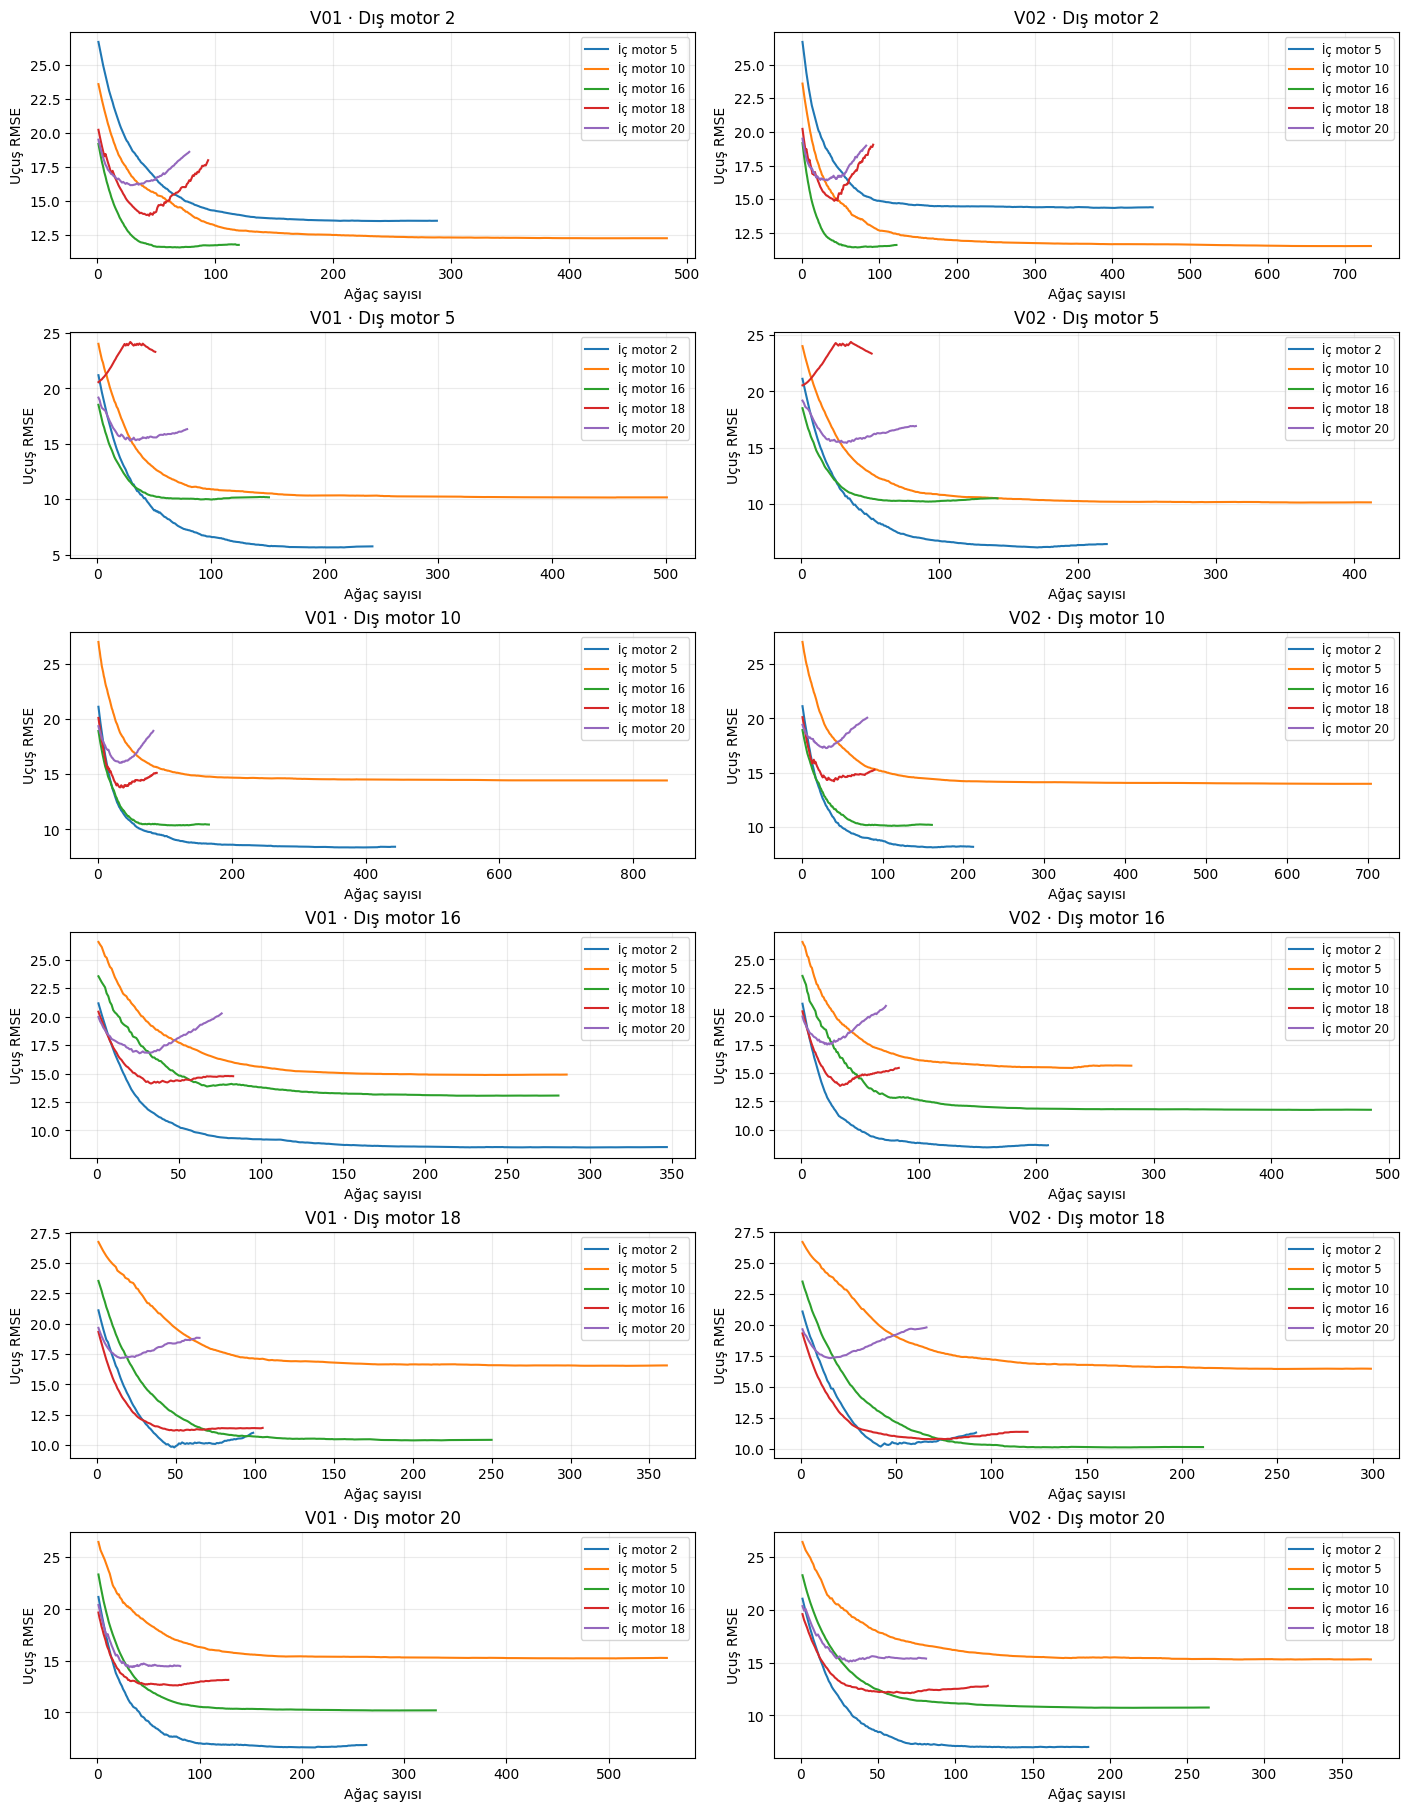

In [4]:
curve_fig, axes = plt.subplots(
    len(units), 2, figsize=(14, 3 * len(units)), layout="constrained"
)
for row, outer_unit in enumerate(units):
    for col, version in enumerate(("V01", "V02")):
        ax = axes[row, col]
        curves = inner_curves.loc[
            (inner_curves["Model"] == version) & (inner_curves["Dış motor"] == outer_unit)
        ]
        for inner_unit, curve in curves.groupby("İç motor"):
            ax.plot(curve["Ağaç"], curve["RMSE"], label=f"İç motor {inner_unit}")
        ax.set(title=f"{version} · Dış motor {outer_unit}", xlabel="Ağaç sayısı", ylabel="Uçuş RMSE")
        ax.grid(alpha=0.25)
        ax.legend(fontsize="small")
plt.show()


## Uçuş bazlı sonuçlar

V02’de her uçuş için pencere tahminlerinin medyanı alınır. MAE ve RMSE her
uçuşa eşit ağırlık verir ve yalnızca dış kat tahminlerinden hesaplanır.

In [5]:
v02_flights = v02_oof.groupby(FLIGHT_KEYS, as_index=False).agg(
    RUL=("RUL", "first"), V02=("V02", "median")
)
flight_predictions = v01_oof.merge(
    v02_flights, on=FLIGHT_KEYS, validate="one_to_one", suffixes=("", "_v02")
).sort_values(FLIGHT_KEYS, ignore_index=True)
assert len(flight_predictions) == len(v01_oof) == len(v02_flights) == 446
np.testing.assert_array_equal(flight_predictions["RUL"], flight_predictions["RUL_v02"])
flight_predictions = flight_predictions.drop(columns="RUL_v02")

metric_rows = []
for label, flights in [*flight_predictions.groupby("unit"), ("Tümü", flight_predictions)]:
    for version in ("V01", "V02"):
        errors = flights[version] - flights["RUL"]
        metric_rows.append({
            "motor": label, "model": version, "Uçuş sayısı": len(flights),
            "MAE": errors.abs().mean(), "RMSE": np.sqrt(errors.pow(2).mean()),
        })
metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

,motor,model,Uçuş sayısı,MAE,RMSE
0,2,V01,75,6.250,8.408
1,2,V02,75,6.024,8.019
2,5,V01,89,10.636,14.747
3,5,V02,89,10.836,14.924
4,10,V01,82,8.778,11.751
5,10,V02,82,8.497,11.457
6,16,V01,63,7.728,10.303
7,16,V02,63,7.719,10.268
8,18,V01,71,11.100,13.613
9,18,V02,71,11.772,14.371


## Motor grafikleri

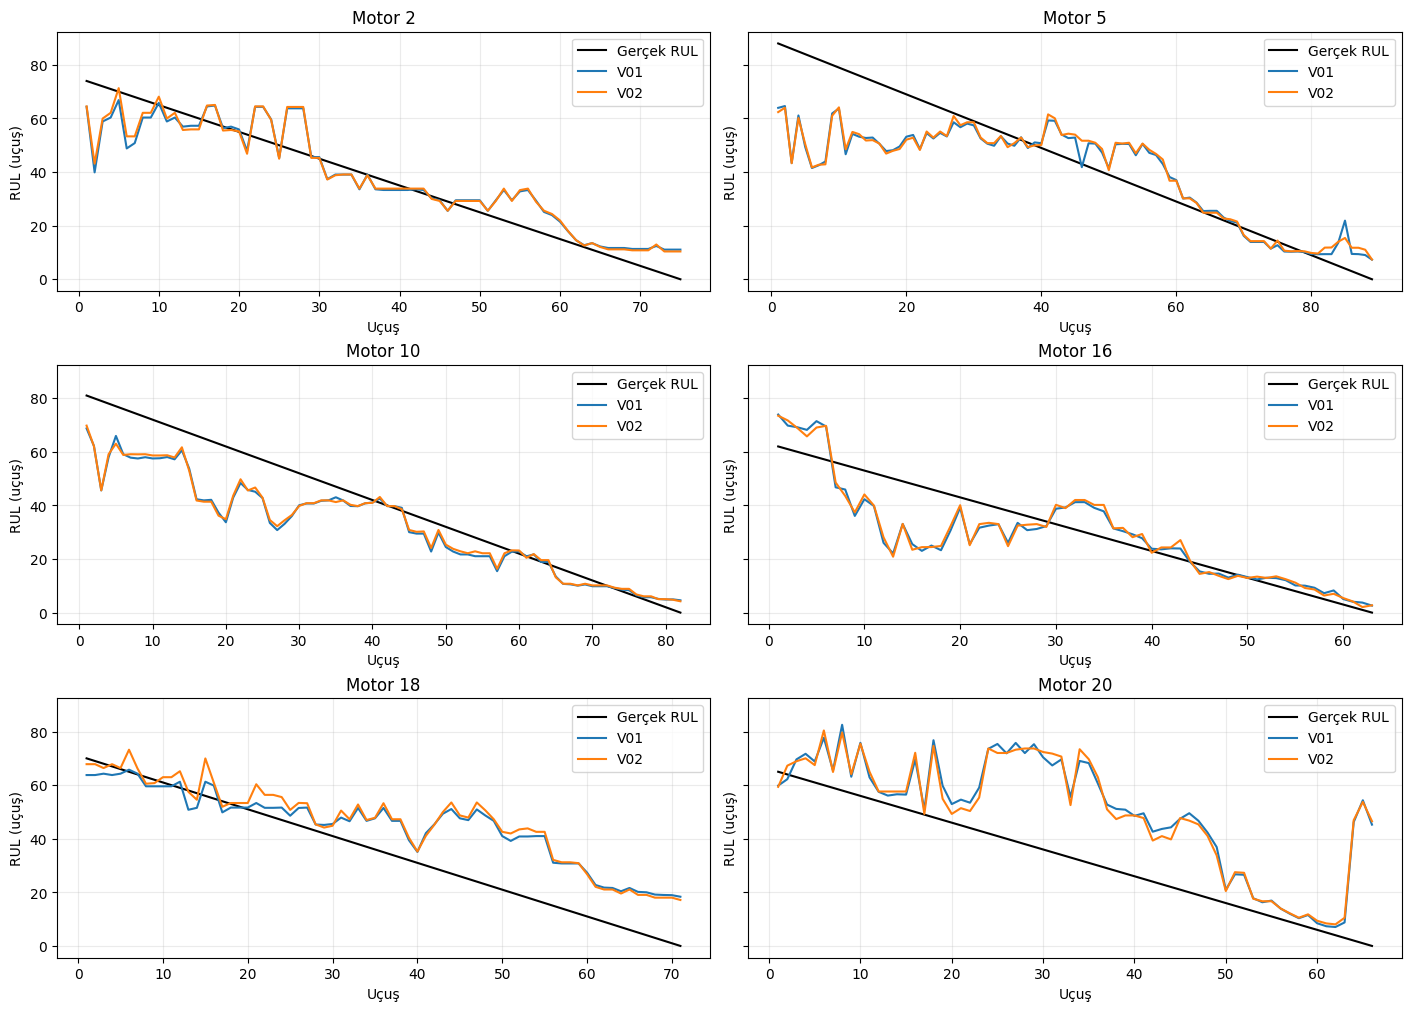

In [6]:
prediction_fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True, layout="constrained")
for ax, (unit, flights) in zip(axes.flat, flight_predictions.groupby("unit")):
    ax.plot(flights["cycle"], flights["RUL"], label="Gerçek RUL", color="black")
    ax.plot(flights["cycle"], flights["V01"], label="V01")
    ax.plot(flights["cycle"], flights["V02"], label="V02")
    ax.set(title=f"Motor {unit}", xlabel="Uçuş", ylabel="RUL (uçuş)")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Drive kaydı

In [ ]:
output_dir.mkdir(parents=True, exist_ok=True)
v02.to_parquet(output_dir / "v02_ozellikler.parquet", index=False, engine="pyarrow")
flight_predictions.to_csv(output_dir / "ucus_tahminleri.csv", index=False, encoding="utf-8-sig")
metrics.to_csv(output_dir / "karsilastirma_metrikleri.csv", index=False, encoding="utf-8-sig")
print(output_dir)
inner_folds.to_csv(output_dir / "ic_kat_agac_sayilari.csv", index=False, encoding="utf-8-sig")
inner_summary.to_csv(output_dir / "ic_kat_ozeti.csv", index=False, encoding="utf-8-sig")
inner_curves.to_csv(output_dir / "ic_dogrulama_egrileri.csv", index=False, encoding="utf-8-sig")
prediction_fig.savefig(output_dir / "motor_tahminleri.png", dpi=150)
curve_fig.savefig(output_dir / "ic_dogrulama_egrileri.png", dpi=150)